## model training using vgg19

import libraries and settings

In [1]:
import tensorflow as tf
from tensorflow.keras.applications import VGG19
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

In [2]:
# image resize dimensions
image_size = (224, 224)

# batch size
batch_size = 32

# dataset directory (update if needed)
dataset_path = "../dataset_8"

In [12]:
train_data_generator = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    validation_split=0.3,
    rotation_range=30,            # more rotation (was 15)
    width_shift_range=0.2,        # more horizontal shift (was 0.1)
    height_shift_range=0.2,       # more vertical shift (was 0.1)
    zoom_range=0.3,               # stronger zoom (was 0.1)
    shear_range=0.2,              # adds shearing for geometric distortion
    brightness_range=[0.7, 1.3],  # vary brightness more
    horizontal_flip=True,         
    fill_mode='nearest'           # standard for filling pixels after transforms
)

validation_data_generator = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    validation_split=0.3
)

VGG19 has more parameters, so it's more prone to overfitting on this small dataset. Therefore, stronger augmentation helps combat this.

In [13]:
training_generator = train_data_generator.flow_from_directory(
    dataset_path,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=42  # for reproducibility
)

validation_generator = validation_data_generator.flow_from_directory(
    dataset_path,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=42  # for reproducibility
)

Found 336 images belonging to 4 classes.


Found 144 images belonging to 4 classes.


In [15]:
# load VGG19 without the top classification layers, using imagenet weights
base_model = VGG19(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # freeze the base model

model = Sequential([
    base_model,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(4, activation='softmax')
])

model.compile(optimizer=Adam(learning_rate=1e-4),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg19 (Functional)              │ (None, 7, 7, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,448,196 (100.89 MB)

 Trainable params: 6,423,812 (24.50 MB)

 Non-trainable params: 20,024,384 (76.39 MB)

In [ ]:
early_stop = EarlyStopping(patience=5, restore_best_weights=True)

# initial training
history = model.fit(
    training_generator,
    epochs=20,
    validation_data=validation_generator,
    callbacks=[early_stop]
)

c:\Users\user\Desktop\csc3109-ml_project\venv\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 78s 7s/step - accuracy: 0.2839 - loss: 1.6185 - val_accuracy: 0.4167 - val_loss: 1.2398
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 79s 7s/step - accuracy: 0.4164 - loss: 1.2976 - val_accuracy: 0.5486 - val_loss: 1.1718
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 79s 7s/step - accuracy: 0.5208 - loss: 1.0888 - val_accuracy: 0.5417 - val_loss: 1.0860
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 81s 8s/step - accuracy: 0.6278 - loss: 0.9723 - val_accuracy: 0.5625 - val_loss: 1.0854
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 94s 9s/step - accuracy: 0.5470 - loss: 1.0962 - val_accuracy: 0.4792 - val_loss: 1.2548
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 109s 10s/step - accuracy: 0.5841 - loss: 1.0157 - val_accuracy: 0.6111 - val_loss: 0.9934
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 94s 9s/step - accuracy: 0.6364 - loss: 0.9408 - val_accuracy: 0.5069 - val_loss: 1.1984
Epoch 8/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 91s 8s/step - accuracy: 0.6228 - loss: 0.9504 - val_accuracy: 0.5694 - val_los

- initial training shows progressive improvement in both training and validation accuracy.
- early stopping didn't trigger within 20 epochs, implying room for further learning, but results start plateauing after epoch 10.
- slight fluctuations in validation accuracy after epoch 6 indicate mild overfitting signs.
- validation loss doesn't consistently decrease, this suggests model is near its limit under current settings.

In [ ]:
# fine-tuning
base_model.trainable = True
model.compile(optimizer=Adam(learning_rate=1e-5),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history_fine = model.fit(
    training_generator,
    epochs=10,
    validation_data=validation_generator,
    callbacks=[early_stop]
)

Epoch 1/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 211s 19s/step - accuracy: 0.6400 - loss: 0.8904 - val_accuracy: 0.5972 - val_loss: 0.9145
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 233s 21s/step - accuracy: 0.7078 - loss: 0.7113 - val_accuracy: 0.6597 - val_loss: 0.9238
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 271s 25s/step - accuracy: 0.7374 - loss: 0.6275 - val_accuracy: 0.6667 - val_loss: 0.8859
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 308s 29s/step - accuracy: 0.7541 - loss: 0.6545 - val_accuracy: 0.6875 - val_loss: 1.0469
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 300s 27s/step - accuracy: 0.7943 - loss: 0.4998 - val_accuracy: 0.7222 - val_loss: 0.8141
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 400s 38s/step - accuracy: 0.8090 - loss: 0.5601 - val_accuracy: 0.7014 - val_loss: 1.0098
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 355s 32s/step - accuracy: 0.8267 - loss: 0.4900 - val_accuracy: 0.7083 - val_loss: 0.9644
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 348s 32s/step - accuracy: 0.8832 - loss: 0.3507 - val_accuracy: 0.

- fine-tuning with a small learning rate significantly boosts performance.
- model reaches 90%+ training accuracy and 78%+ validation accuracy by the end.
- training time per epoch increased substantially (from ~90s to ~300-400s), expected when unfreezing base model.

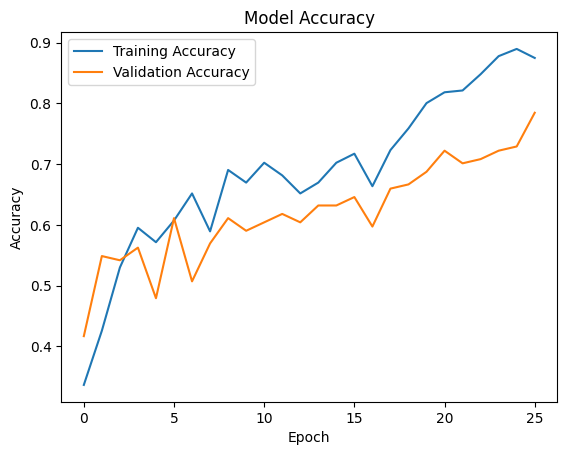

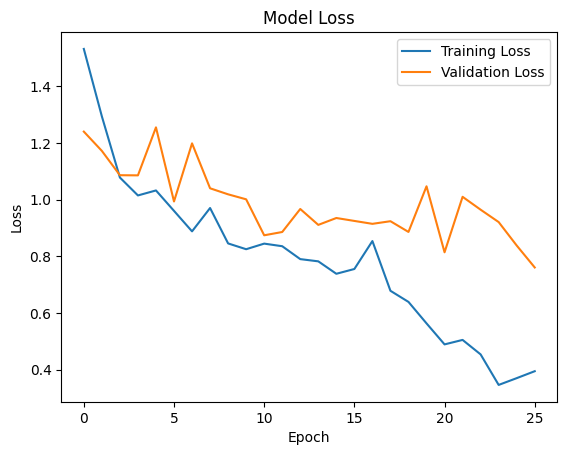

In [18]:
# plot accuracy
plt.plot(history.history['accuracy'] + history_fine.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'] + history_fine.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# plot loss
plt.plot(history.history['loss'] + history_fine.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'] + history_fine.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()